In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words"
)

METADATA_PATH = PROJECT_DIR / "landmark_metadata.csv"

metadata = pd.read_csv(METADATA_PATH, header=None)

for i in range(5):
    print(f"Row {i}:", metadata.iloc[i, 0])

print("\nFeature path examples:")
for p in metadata.iloc[0, :5]:
    print(p)

Mounted at /content/drive
Row 0: /content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MediaPipe_Landmarks/03/train/0171/03_03_0171_(18_04_17_17_29_53)_c.npy
Row 1: 03_03_0171_(18_04_17_17_29_53)_c.mp4
Row 2: 30.0
Row 3: 66
Row 4: 29

Feature path examples:
/content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MediaPipe_Landmarks/03/train/0171/03_03_0171_(18_04_17_17_29_53)_c.npy
/content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MediaPipe_Landmarks/03/train/0171/03_03_0171_(18_04_17_17_29_57)_c.npy
/content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MediaPipe_Landmarks/03/train/0171/03_03_0171_(18_04_17_17_30_01)_c.npy
/content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MediaPipe_Landmarks/03/train/0171/03_03_0171_(18_04_17_17_30_06)_c.npy
/content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MediaPipe_Landmarks/03/train/0171/03_03_0171_(18_04_17_17_30_11)_c.npy


## **Load Dataset**


In [3]:
# ==========================================
# LOAD DATASET
# ==========================================

import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words"
)

METADATA_PATH = PROJECT_DIR / "landmark_metadata.csv"

# Load metadata: feature paths are stored in row 0
metadata_raw = pd.read_csv(METADATA_PATH, header=None, dtype=str)

feature_paths = metadata_raw.iloc[0].dropna().tolist()
feature_paths = list(dict.fromkeys(p.strip() for p in feature_paths if p.strip()))

print("Feature paths found:", len(feature_paths))

# ==========================================
# LOAD FEATURES AND EXTRACT LABELS
# ==========================================

X_list = []
sign_ids = []
signers = []
splits = []
loaded_paths = []
failed_files = []

for feature_path in feature_paths:

    path = Path(feature_path)

    try:
        # Extract information from folder structure:
        # MediaPipe_Landmarks / signer / split / sign_id / file.npy

        parts = path.parts
        landmark_idx = parts.index("MediaPipe_Landmarks")

        signer = parts[landmark_idx + 1]
        split = parts[landmark_idx + 2].lower()
        sign_id = parts[landmark_idx + 3]

        if split not in ("train", "test"):
            raise ValueError(f"Unknown split: {split}")

        if sign_id not in [f"{i:04d}" for i in range(171, 191)]:
            raise ValueError(f"Unexpected sign ID: {sign_id}")

        # Load feature array
        features = np.load(path, allow_pickle=False)

        if features.shape != (30, 90):
            raise ValueError(f"Unexpected shape: {features.shape}")

        if not np.issubdtype(features.dtype, np.number):
            raise ValueError("Non-numeric features")

        if np.isinf(features).any():
            raise ValueError("Features contain Inf")

        X_list.append(features.astype(np.float32))
        sign_ids.append(sign_id)
        signers.append(signer)
        splits.append(split)
        loaded_paths.append(str(path))

    except Exception as e:
        failed_files.append({
            "path": str(path),
            "error": repr(e)
        })


# ==========================================
# CONVERT TO NUMPY ARRAYS
# ==========================================

X = np.stack(X_list)

# Encode classes as integers: 0 to 19
classes = sorted(set(sign_ids))
class_to_idx = {sign_id: idx for idx, sign_id in enumerate(classes)}

y = np.array([class_to_idx[s] for s in sign_ids], dtype=np.int64)

signers = np.array(signers)
splits = np.array(splits)
sign_ids = np.array(sign_ids)

# ==========================================
# DISPLAY DATASET INFORMATION
# ==========================================

print("\n" + "=" * 50)
print("DATASET LOADED")
print("=" * 50)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of classes:", len(classes))
print("Classes:", classes)
print("Number of signers:", len(np.unique(signers)))

print("\nTrain videos:", np.sum(splits == "train"))
print("Test videos:", np.sum(splits == "test"))

print("Failed files:", len(failed_files))

print("\n--- Videos per Signer and Split ---")

dataset_info = pd.DataFrame({
    "signer": signers,
    "split": splits,
    "sign_id": sign_ids
})

display(
    dataset_info.groupby(["signer", "split"]).size().unstack(fill_value=0)
)

print("\n--- Videos per Class ---")

display(
    dataset_info.groupby(["sign_id", "split"]).size().unstack(fill_value=0)
)

if failed_files:
    print("\nFirst failed files:")
    display(pd.DataFrame(failed_files).head(10))

Feature paths found: 2879

DATASET LOADED
X shape: (2879, 30, 90)
y shape: (2879,)
Number of classes: 20
Classes: ['0171', '0172', '0173', '0174', '0175', '0176', '0177', '0178', '0179', '0180', '0181', '0182', '0183', '0184', '0185', '0186', '0187', '0188', '0189', '0190']
Number of signers: 3

Train videos: 2399
Test videos: 480
Failed files: 0

--- Videos per Signer and Split ---


split,test,train
signer,,
01,160,844
02,160,851
03,160,704



--- Videos per Class ---


split,test,train
sign_id,,
0171,24,132
0172,24,127
0173,24,126
0174,24,127
0175,24,100
0176,24,127
0177,24,128
0178,24,127
0179,24,126


## **Train / Validation / Test Split**

In [4]:
# ==========================================
# TRAIN / VALIDATION / TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
VALIDATION_SIZE = 0.20

# Original predefined splits
train_indices = np.where(splits == "train")[0]
test_indices = np.where(splits == "test")[0]

# Keep the original test set completely untouched
X_test_raw = X[test_indices]
y_test = y[test_indices]

test_signers = signers[test_indices]

# Split only the original training data
X_original_train = X[train_indices]
y_original_train = y[train_indices]

train_signers = signers[train_indices]
train_sign_ids = sign_ids[train_indices]

# Stratify using signer + sign class
stratify_labels = np.array([
    f"{signer}_{sign_id}"
    for signer, sign_id in zip(train_signers, train_sign_ids)
])

# Check whether every signer-class group has enough samples
group_counts = pd.Series(stratify_labels).value_counts()

if group_counts.min() >= 2:
    stratification = stratify_labels
    print("Stratification: Signer + Sign Class")
else:
    stratification = y_original_train
    print("Stratification: Sign Class only (some signer-class groups are too small)")

# Create training and validation indices
train_idx, val_idx = train_test_split(
    np.arange(len(X_original_train)),
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=stratification
)

# Final datasets
X_train_raw = X_original_train[train_idx]
y_train = y_original_train[train_idx]

X_val_raw = X_original_train[val_idx]
y_val = y_original_train[val_idx]

# Corresponding signer information
train_signers_final = train_signers[train_idx]
val_signers = train_signers[val_idx]

# ==========================================
# DISPLAY SPLIT INFORMATION
# ==========================================

print("\n" + "=" * 50)
print("DATASET SPLIT")
print("=" * 50)

print(f"Training:   {len(X_train_raw)} videos")
print(f"Validation: {len(X_val_raw)} videos")
print(f"Testing:    {len(X_test_raw)} videos")

print("\nShapes:")
print("X_train:", X_train_raw.shape)
print("X_val:  ", X_val_raw.shape)
print("X_test: ", X_test_raw.shape)

print("\n--- Signer Distribution ---")

split_info = pd.DataFrame({
    "signer": np.concatenate([
        train_signers_final,
        val_signers,
        test_signers
    ]),
    "split": (
        ["train"] * len(train_signers_final) +
        ["validation"] * len(val_signers) +
        ["test"] * len(test_signers)
    )
})

display(
    split_info.groupby(["signer", "split"])
    .size()
    .unstack(fill_value=0)
)

print("\n--- Class Distribution ---")

class_info = pd.DataFrame({
    "class": np.concatenate([y_train, y_val, y_test]),
    "split": (
        ["train"] * len(y_train) +
        ["validation"] * len(y_val) +
        ["test"] * len(y_test)
    )
})

display(
    class_info.groupby(["class", "split"])
    .size()
    .unstack(fill_value=0)
)

# Verify no overlap between train, validation and test
assert len(train_idx) + len(val_idx) == len(train_indices)
assert len(X_test_raw) == len(test_indices)

print("\nSplit verification passed!")

Stratification: Signer + Sign Class

DATASET SPLIT
Training:   1919 videos
Validation: 480 videos
Testing:    480 videos

Shapes:
X_train: (1919, 30, 90)
X_val:   (480, 30, 90)
X_test:  (480, 30, 90)

--- Signer Distribution ---


split,test,train,validation
signer,,,
01,160,677,167
02,160,678,173
03,160,564,140



--- Class Distribution ---


split,test,train,validation
class,,,
0,24,105,27
1,24,102,25
2,24,101,25
3,24,102,25
4,24,80,20
5,24,101,26
6,24,103,25
7,24,101,26
8,24,101,25



Split verification passed!


## **Data Preparation**

In [6]:
# ==========================================
# DATA PREPARATION — CORRECTED
# ==========================================

from sklearn.preprocessing import StandardScaler

FRAMES = 30
COORD_FEATURES = 88
FLAG_FEATURES = 2

# ==========================================
# 1. SEPARATE COORDINATES AND FLAGS
# ==========================================

# Keep the original 3D structure for now
train_3d = X_train_raw.copy()
val_3d = X_val_raw.copy()
test_3d = X_test_raw.copy()

# Separate coordinates and detection flags
train_coords = train_3d[:, :, :COORD_FEATURES]
val_coords = val_3d[:, :, :COORD_FEATURES]
test_coords = test_3d[:, :, :COORD_FEATURES]

train_flags = train_3d[:, :, COORD_FEATURES:]
val_flags = val_3d[:, :, COORD_FEATURES:]
test_flags = test_3d[:, :, COORD_FEATURES:]

print("Coordinates:", train_coords.shape)
print("Detection flags:", train_flags.shape)


# ==========================================
# 2. HANDLE MISSING COORDINATES
# ==========================================

# Calculate the mean for each frame and coordinate
# using TRAINING DATA ONLY.

coordinate_means = np.nanmean(train_coords, axis=0)

# Handle any coordinate that is entirely missing
coordinate_means = np.nan_to_num(
    coordinate_means,
    nan=0.0
)

# Impute missing values
train_coords = np.where(
    np.isfinite(train_coords),
    train_coords,
    coordinate_means[np.newaxis, :, :]
)

val_coords = np.where(
    np.isfinite(val_coords),
    val_coords,
    coordinate_means[np.newaxis, :, :]
)

test_coords = np.where(
    np.isfinite(test_coords),
    test_coords,
    coordinate_means[np.newaxis, :, :]
)

print("\nMissing coordinates imputed.")


# ==========================================
# 3. NORMALIZE COORDINATES ONLY
# ==========================================

scaler = StandardScaler()

# Flatten coordinates temporarily for scaling
train_coords_flat = train_coords.reshape(len(train_coords), -1)
val_coords_flat = val_coords.reshape(len(val_coords), -1)
test_coords_flat = test_coords.reshape(len(test_coords), -1)

# Fit only on training data
train_coords_scaled = scaler.fit_transform(train_coords_flat)

val_coords_scaled = scaler.transform(val_coords_flat)
test_coords_scaled = scaler.transform(test_coords_flat)


# ==========================================
# 4. RECOMBINE COORDINATES AND FLAGS
# ==========================================

# Reshape normalized coordinates back to 3D
train_coords_scaled = train_coords_scaled.reshape(-1, FRAMES, COORD_FEATURES)
val_coords_scaled = val_coords_scaled.reshape(-1, FRAMES, COORD_FEATURES)
test_coords_scaled = test_coords_scaled.reshape(-1, FRAMES, COORD_FEATURES)

# Combine coordinates with ORIGINAL binary detection flags
X_train = np.concatenate(
    [train_coords_scaled, train_flags],
    axis=2
)

X_val = np.concatenate(
    [val_coords_scaled, val_flags],
    axis=2
)

X_test = np.concatenate(
    [test_coords_scaled, test_flags],
    axis=2
)

# Flatten for MLP input
X_train = X_train.reshape(len(X_train), -1)
X_val = X_val.reshape(len(X_val), -1)
X_test = X_test.reshape(len(X_test), -1)


# ==========================================
# 5. FINAL VALIDATION
# ==========================================

print("\n" + "=" * 50)
print("DATA PREPARATION COMPLETE")
print("=" * 50)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nNaN values:")
print("Train:", np.isnan(X_train).sum())
print("Validation:", np.isnan(X_val).sum())
print("Test:", np.isnan(X_test).sum())

print("\nInf values:")
print("Train:", np.isinf(X_train).sum())
print("Validation:", np.isinf(X_val).sum())
print("Test:", np.isinf(X_test).sum())

print("\nDetection flag values:")
print("Train:", np.unique(X_train[:, 88::90]))
print("Validation:", np.unique(X_val[:, 88::90]))
print("Test:", np.unique(X_test[:, 88::90]))

# Verify dimensions
assert X_train.shape == (1919, 2700)
assert X_val.shape == (480, 2700)
assert X_test.shape == (480, 2700)

# Verify no missing or infinite values
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

# Verify flags remain binary
assert np.isin(X_train[:, 88::90], [0, 1]).all()
assert np.isin(X_train[:, 89::90], [0, 1]).all()

print("\nAll checks passed!")

Coordinates: (1919, 30, 88)
Detection flags: (1919, 30, 2)

Missing coordinates imputed.

DATA PREPARATION COMPLETE
Training: (1919, 2700)
Validation: (480, 2700)
Testing: (480, 2700)

NaN values:
Train: 0
Validation: 0
Test: 0

Inf values:
Train: 0
Validation: 0
Test: 0

Detection flag values:
Train: [0. 1.]
Validation: [0. 1.]
Test: [0. 1.]

All checks passed!


# **Build MLP**

In [7]:
# ==========================================
# BUILD MLP MODEL
# ==========================================

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Model configuration
INPUT_DIM = X_train.shape[1]
NUM_CLASSES = len(classes)

# ==========================================
# MLP ARCHITECTURE
# ==========================================

model = models.Sequential([

    # Input layer
    layers.Input(shape=(INPUT_DIM,)),

    # Hidden Layer 1
    layers.Dense(
        512,
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.4),

    # Hidden Layer 2
    layers.Dense(
        256,
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),

    # Hidden Layer 3
    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.2),

    # Output Layer
    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

# ==========================================
# COMPILE MODEL
# ==========================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ==========================================
# MODEL SUMMARY
# ==========================================

model.summary()

print("\nInput features:", INPUT_DIM)
print("Output classes:", NUM_CLASSES)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     1,382,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,552,788 (5.92 MB)

 Trainable params: 1,551,252 (5.92 MB)

 Non-trainable params: 1,536 (6.00 KB)


Input features: 2700
Output classes: 20


## **Training**

In [8]:
# ==========================================
# TRAINING
# ==========================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

import time

# Training configuration
EPOCHS = 100
BATCH_SIZE = 32

# Save best model
MODEL_DIR = PROJECT_DIR / "MLP_Results"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_mlp.keras"

# ==========================================
# CALLBACKS
# ==========================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath=str(BEST_MODEL_PATH),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callbacks = [
    early_stopping,
    reduce_lr,
    checkpoint
]

# ==========================================
# TRAIN MODEL
# ==========================================

start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

training_time = time.time() - start_time

print("\n" + "=" * 50)
print("TRAINING COMPLETE")
print("=" * 50)

print(f"Training time: {training_time / 60:.2f} minutes")
print(f"Epochs completed: {len(history.history['loss'])}")
print(f"Best validation accuracy: {max(history.history['val_accuracy']):.4f}")
print(f"Best validation loss: {min(history.history['val_loss']):.4f}")
print(f"Best model saved at: {BEST_MODEL_PATH}")

Epoch 1/100
58/60 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.4812 - loss: 3.1816
Epoch 1: val_loss improved from None to 1.57690, saving model to /content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MLP_Results/best_mlp.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MLP_Results/best_mlp.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.6696 - loss: 2.5082 - val_accuracy: 0.9000 - val_loss: 1.5769 - learning_rate: 0.0010
Epoch 2/100
59/60 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8870 - loss: 1.6500
Epoch 2: val_loss improved from 1.57690 to 1.30306, saving model to /content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MLP_Results/best_mlp.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MLP_Results/best_mlp.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9031 - loss: 1.5660 - val_accuracy: 0.9583 - val_loss: 1.3031 - lea

## **Evaluation**

MLP - TEST RESULTS
Test Loss:       0.1026
Test Accuracy:   0.9958 (99.58%)
Macro Precision:0.9960
Macro Recall:    0.9958
Macro F1-score:  0.9958

Classification Report:
              precision    recall  f1-score   support

        0171       1.00      1.00      1.00        24
        0172       1.00      1.00      1.00        24
        0173       1.00      0.96      0.98        24
        0174       1.00      1.00      1.00        24
        0175       1.00      0.96      0.98        24
        0176       1.00      1.00      1.00        24
        0177       1.00      1.00      1.00        24
        0178       1.00      1.00      1.00        24
        0179       1.00      1.00      1.00        24
        0180       1.00      1.00      1.00        24
        0181       1.00      1.00      1.00        24
        0182       1.00      1.00      1.00        24
        0183       0.96      1.00      0.98        24
        0184       1.00      1.00      1.00        24
        0185      

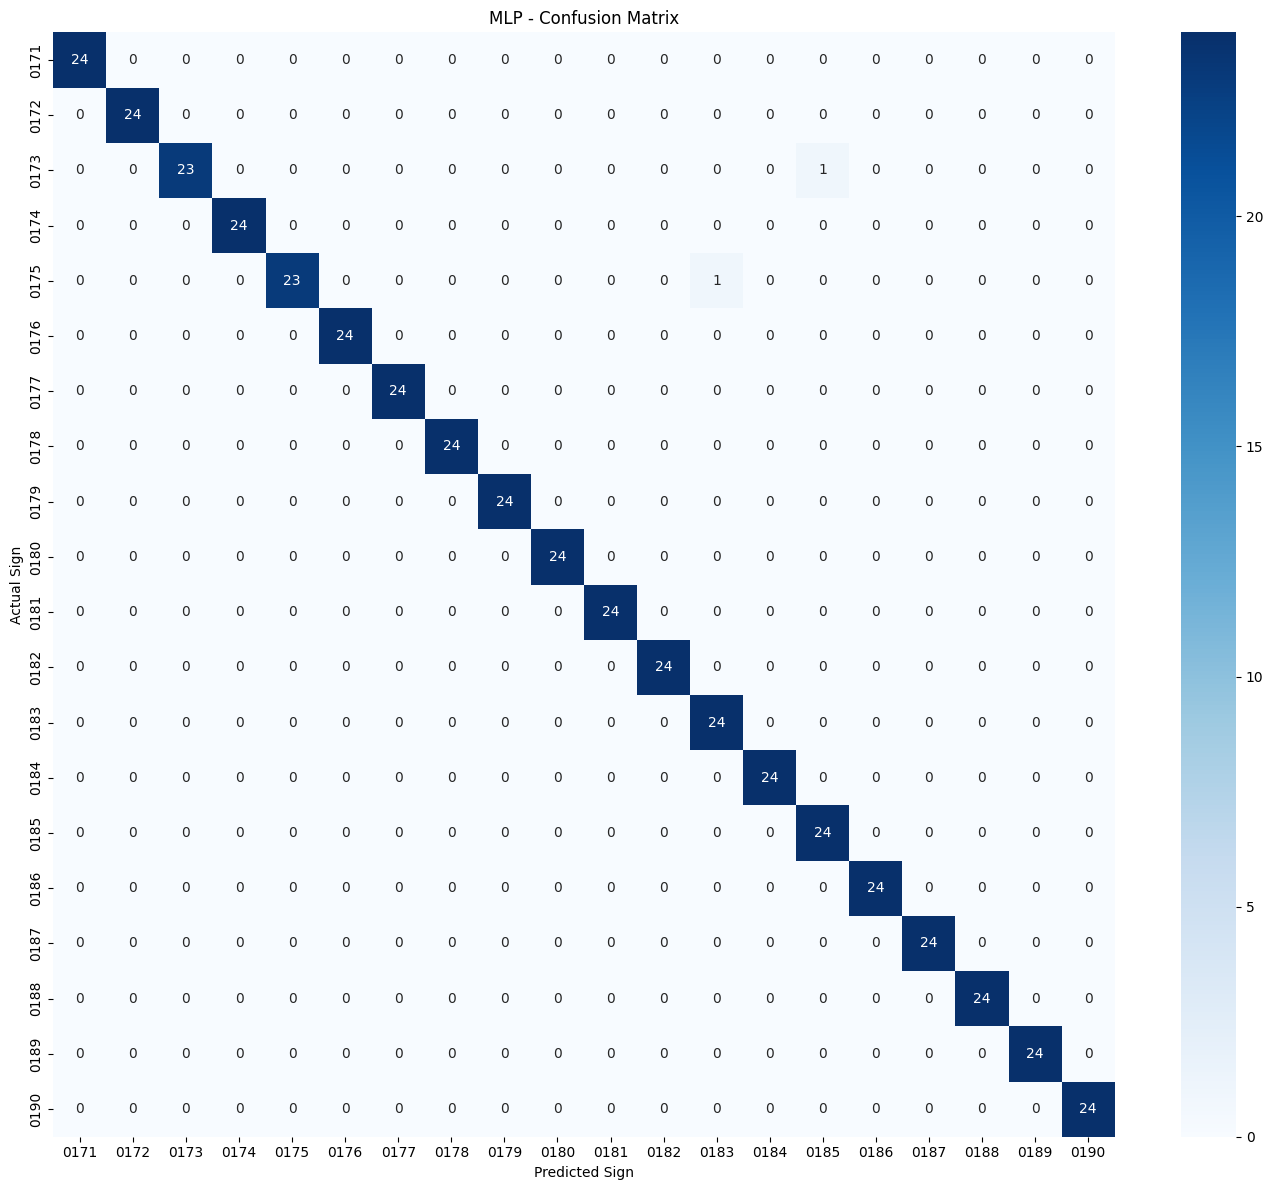


Prediction Summary:
Correct predictions:   478/480
Incorrect predictions: 2/480


In [9]:
# ==========================================
# TEST SET EVALUATION
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import load_model
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Load the best saved model
model = load_model(BEST_MODEL_PATH)

# ==========================================
# PREDICTIONS
# ==========================================

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# ==========================================
# METRICS
# ==========================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("=" * 50)
print("MLP - TEST RESULTS")
print("=" * 50)

print(f"Test Loss:       {test_loss:.4f}")
print(f"Test Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro Precision:{precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1-score:  {f1:.4f}")

# ==========================================
# CLASSIFICATION REPORT
# ==========================================

report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
)

print("\nClassification Report:")
print(report)

# ==========================================
# CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(classes))
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("MLP - Confusion Matrix")
plt.xlabel("Predicted Sign")
plt.ylabel("Actual Sign")
plt.tight_layout()
plt.show()

# ==========================================
# CORRECT / INCORRECT PREDICTIONS
# ==========================================

correct = np.sum(y_test == y_pred)
incorrect = np.sum(y_test != y_pred)

print("\nPrediction Summary:")
print(f"Correct predictions:   {correct}/{len(y_test)}")
print(f"Incorrect predictions: {incorrect}/{len(y_test)}")

In [10]:
# Show the two misclassified videos

wrong_indices = np.where(y_test != y_pred)[0]

for idx in wrong_indices:
    print(f"Test sample: {idx}")
    print(f"Actual sign:    {classes[y_test[idx]]}")
    print(f"Predicted sign: {classes[y_pred[idx]]}")
    print(f"Confidence:     {np.max(y_prob[idx]) * 100:.2f}%")
    print("-" * 40)

Test sample: 337
Actual sign:    0173
Predicted sign: 0185
Confidence:     63.08%
----------------------------------------
Test sample: 359
Actual sign:    0175
Predicted sign: 0183
Confidence:     61.07%
----------------------------------------


In [11]:
# Top 3 predictions for each misclassified sample

for idx in wrong_indices:
    top_3 = np.argsort(y_prob[idx])[-3:][::-1]

    print(f"\nTest sample: {idx}")
    print(f"Actual sign: {classes[y_test[idx]]}")

    for rank, class_idx in enumerate(top_3, start=1):
        print(
            f"{rank}. Sign {classes[class_idx]} "
            f"— {y_prob[idx][class_idx] * 100:.2f}%"
        )


Test sample: 337
Actual sign: 0173
1. Sign 0185 — 63.08%
2. Sign 0173 — 36.17%
3. Sign 0177 — 0.41%

Test sample: 359
Actual sign: 0175
1. Sign 0183 — 61.07%
2. Sign 0175 — 37.84%
3. Sign 0179 — 0.36%


## **Save Model and Results**

In [12]:
# ==========================================
# SAVE MLP MODEL AND RESULTS
# ==========================================

import json
import joblib
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report

# Results directory
RESULTS_DIR = PROJECT_DIR / "MLP_Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 1. SAVE MODEL
# ==========================================

FINAL_MODEL_PATH = RESULTS_DIR / "final_mlp.keras"

model.save(FINAL_MODEL_PATH)

print("Model saved:", FINAL_MODEL_PATH)

# ==========================================
# 2. SAVE PREPROCESSING OBJECTS
# ==========================================

joblib.dump(scaler, RESULTS_DIR / "scaler.pkl")

np.save(
    RESULTS_DIR / "coordinate_means.npy",
    coordinate_means
)

# Save class mapping
with open(RESULTS_DIR / "class_mapping.json", "w") as f:
    json.dump(
        {
            "classes": [str(c) for c in classes],
            "class_to_idx": {
                str(k): int(v) for k, v in class_to_idx.items()
            }
        },
        f,
        indent=4
    )

print("Preprocessing objects saved.")

# ==========================================
# 3. SAVE TEST METRICS
# ==========================================

metrics = {
    "model": "MLP",
    "test_samples": int(len(y_test)),
    "correct_predictions": int(correct),
    "incorrect_predictions": int(incorrect),
    "test_accuracy": float(accuracy),
    "test_loss": float(test_loss),
    "macro_precision": float(precision),
    "macro_recall": float(recall),
    "macro_f1_score": float(f1),
    "best_validation_accuracy": float(max(history.history["val_accuracy"])),
    "best_validation_loss": float(min(history.history["val_loss"]))
}

with open(RESULTS_DIR / "test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# ==========================================
# 4. SAVE CLASSIFICATION REPORT
# ==========================================

report_dict = classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    RESULTS_DIR / "classification_report.csv"
)

# ==========================================
# 5. SAVE CONFUSION MATRIX
# ==========================================

pd.DataFrame(
    cm,
    index=classes,
    columns=classes
).to_csv(RESULTS_DIR / "confusion_matrix.csv")

# ==========================================
# 6. SAVE TRAINING HISTORY
# ==========================================

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    RESULTS_DIR / "training_history.csv",
    index=False
)

# ==========================================
# 7. SAVE TEST PREDICTIONS
# ==========================================

predictions_df = pd.DataFrame({
    "Actual": [classes[i] for i in y_test],
    "Predicted": [classes[i] for i in y_pred],
    "Confidence": np.max(y_prob, axis=1),
    "Correct": y_test == y_pred
})

predictions_df.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False
)

# ==========================================
# 8. SAVE MISCLASSIFIED SAMPLES
# ==========================================

wrong_indices = np.where(y_test != y_pred)[0]

errors_df = predictions_df.iloc[wrong_indices].copy()

errors_df.insert(
    0,
    "Test_Sample",
    wrong_indices
)

errors_df.to_csv(
    RESULTS_DIR / "misclassified_samples.csv",
    index=False
)

# ==========================================
# FINAL SUMMARY
# ==========================================

print("\n" + "=" * 50)
print("ALL MLP RESULTS SAVED SUCCESSFULLY!")
print("=" * 50)

print("\nSaved files:")

for file in sorted(RESULTS_DIR.iterdir()):
    print(f"- {file.name}")

print("\nFinal Test Accuracy:",
      f"{accuracy * 100:.2f}%")

print("Correct Predictions:", correct)
print("Incorrect Predictions:", incorrect)

print("\nResults folder:")
print(RESULTS_DIR)

Model saved: /content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MLP_Results/final_mlp.keras
Preprocessing objects saved.

ALL MLP RESULTS SAVED SUCCESSFULLY!

Saved files:
- best_mlp.keras
- class_mapping.json
- classification_report.csv
- confusion_matrix.csv
- coordinate_means.npy
- final_mlp.keras
- misclassified_samples.csv
- scaler.pkl
- test_metrics.json
- test_predictions.csv
- training_history.csv

Final Test Accuracy: 99.58%
Correct Predictions: 478
Incorrect Predictions: 2

Results folder:
/content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/MLP_Results


## **MODEL BUT DIFFERENT SIGNERS TEST**
# Reconstruct the complete dataset

In [13]:
# ==========================================
# LOSO — RECONSTRUCT COMPLETE RAW DATASET
# ==========================================

import numpy as np
import pandas as pd

# Combine raw features
X_all_raw = np.concatenate([
    X_train_raw,
    X_val_raw,
    X_test_raw
], axis=0)

# Combine labels
y_all = np.concatenate([
    y_train,
    y_val,
    y_test
])

# Combine signer IDs
signers_all = np.concatenate([
    train_signers_final,
    val_signers,
    test_signers
])

print("Complete dataset reconstructed")
print("=" * 45)

print("X shape:", X_all_raw.shape)
print("Labels shape:", y_all.shape)
print("Signers shape:", signers_all.shape)

print("\nSigner distribution:")

for signer in np.unique(signers_all):
    count = np.sum(signers_all == signer)
    print(f"Signer {signer}: {count} videos")

print("\nClasses:", len(np.unique(y_all)))

assert len(X_all_raw) == len(y_all) == len(signers_all)
assert X_all_raw.shape[1:] == (30, 90)

print("\nAll checks passed!")

Complete dataset reconstructed
X shape: (2879, 30, 90)
Labels shape: (2879,)
Signers shape: (2879,)

Signer distribution:
Signer 01: 1004 videos
Signer 02: 1011 videos
Signer 03: 864 videos

Classes: 20

All checks passed!


## **Prepare LOSO experiments**

In [14]:
# ==========================================
# STEP 2 — CREATE LOSO SPLITS
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
VALIDATION_SIZE = 0.20

signer_ids = np.unique(signers_all)

LOSO_DATA = {}

for held_out_signer in signer_ids:

    print(f"\nPreparing experiment: Test Signer {held_out_signer}")

    # --------------------------------------
    # 1. Separate training pool and test signer
    # --------------------------------------

    test_mask = signers_all == held_out_signer
    train_pool_indices = np.where(~test_mask)[0]
    test_indices = np.where(test_mask)[0]

    # --------------------------------------
    # 2. Split remaining signers into train/val
    # --------------------------------------

    stratify_labels = np.array([
        f"{signers_all[i]}_{y_all[i]}"
        for i in train_pool_indices
    ])

    train_indices, val_indices = train_test_split(
        train_pool_indices,
        test_size=VALIDATION_SIZE,
        random_state=RANDOM_STATE,
        stratify=stratify_labels
    )

    X_train_raw_loso = X_all_raw[train_indices].copy()
    X_val_raw_loso = X_all_raw[val_indices].copy()
    X_test_raw_loso = X_all_raw[test_indices].copy()

    y_train_loso = y_all[train_indices]
    y_val_loso = y_all[val_indices]
    y_test_loso = y_all[test_indices]

    # --------------------------------------
    # 3. Separate coordinates and flags
    # --------------------------------------

    X_train_coords = X_train_raw_loso[:, :, :88].astype(np.float32)
    X_val_coords = X_val_raw_loso[:, :, :88].astype(np.float32)
    X_test_coords = X_test_raw_loso[:, :, :88].astype(np.float32)

    X_train_flags = X_train_raw_loso[:, :, 88:90].astype(np.float32)
    X_val_flags = X_val_raw_loso[:, :, 88:90].astype(np.float32)
    X_test_flags = X_test_raw_loso[:, :, 88:90].astype(np.float32)

    # --------------------------------------
    # 4. Handle NaN and Inf values
    # --------------------------------------

    X_train_coords[~np.isfinite(X_train_coords)] = np.nan
    X_val_coords[~np.isfinite(X_val_coords)] = np.nan
    X_test_coords[~np.isfinite(X_test_coords)] = np.nan

    # Calculate means using TRAINING data only
    coordinate_means_loso = np.nanmean(
        X_train_coords,
        axis=0
    )

    coordinate_means_loso = np.nan_to_num(
        coordinate_means_loso,
        nan=0.0
    )

    # Impute missing coordinates
    X_train_coords = np.where(
        np.isnan(X_train_coords),
        coordinate_means_loso[None, :, :],
        X_train_coords
    )

    X_val_coords = np.where(
        np.isnan(X_val_coords),
        coordinate_means_loso[None, :, :],
        X_val_coords
    )

    X_test_coords = np.where(
        np.isnan(X_test_coords),
        coordinate_means_loso[None, :, :],
        X_test_coords
    )

    # --------------------------------------
    # 5. Standardize coordinates
    # --------------------------------------

    scaler_loso = StandardScaler()

    scaler_loso.fit(
        X_train_coords.reshape(-1, 88)
    )

    X_train_coords = scaler_loso.transform(
        X_train_coords.reshape(-1, 88)
    ).reshape(-1, 30, 88)

    X_val_coords = scaler_loso.transform(
        X_val_coords.reshape(-1, 88)
    ).reshape(-1, 30, 88)

    X_test_coords = scaler_loso.transform(
        X_test_coords.reshape(-1, 88)
    ).reshape(-1, 30, 88)

    # --------------------------------------
    # 6. Restore detection flags and flatten
    # --------------------------------------

    X_train_loso = np.concatenate(
        [X_train_coords, X_train_flags], axis=2
    ).reshape(len(y_train_loso), -1)

    X_val_loso = np.concatenate(
        [X_val_coords, X_val_flags], axis=2
    ).reshape(len(y_val_loso), -1)

    X_test_loso = np.concatenate(
        [X_test_coords, X_test_flags], axis=2
    ).reshape(len(y_test_loso), -1)

    # --------------------------------------
    # 7. Store experiment
    # --------------------------------------

    LOSO_DATA[str(held_out_signer)] = {
        "X_train": X_train_loso,
        "X_val": X_val_loso,
        "X_test": X_test_loso,

        "y_train": y_train_loso,
        "y_val": y_val_loso,
        "y_test": y_test_loso,

        "scaler": scaler_loso,
        "coordinate_means": coordinate_means_loso
    }

    # --------------------------------------
    # 8. Print verification
    # --------------------------------------

    print("Training:", X_train_loso.shape)
    print("Validation:", X_val_loso.shape)
    print("Testing:", X_test_loso.shape)

    print("Training signers:",
          np.unique(signers_all[train_indices]))

    print("Validation signers:",
          np.unique(signers_all[val_indices]))

    print("Testing signer:",
          np.unique(signers_all[test_indices]))

    assert str(held_out_signer) not in [
        str(s) for s in np.unique(signers_all[train_indices])
    ]

    assert str(held_out_signer) not in [
        str(s) for s in np.unique(signers_all[val_indices])
    ]

    assert np.isfinite(X_train_loso).all()
    assert np.isfinite(X_val_loso).all()
    assert np.isfinite(X_test_loso).all()

print("\n" + "=" * 50)
print("ALL THREE LOSO SPLITS CREATED SUCCESSFULLY!")
print("=" * 50)


Preparing experiment: Test Signer 01
Training: (1500, 2700)
Validation: (375, 2700)
Testing: (1004, 2700)
Training signers: ['02' '03']
Validation signers: ['02' '03']
Testing signer: ['01']

Preparing experiment: Test Signer 02
Training: (1494, 2700)
Validation: (374, 2700)
Testing: (1011, 2700)
Training signers: ['01' '03']
Validation signers: ['01' '03']
Testing signer: ['02']

Preparing experiment: Test Signer 03
Training: (1612, 2700)
Validation: (403, 2700)
Testing: (864, 2700)
Training signers: ['01' '02']
Validation signers: ['01' '02']
Testing signer: ['03']

ALL THREE LOSO SPLITS CREATED SUCCESSFULLY!


## **Build and train the 3 MLP models**

In [15]:
# ==========================================
# STEP 3 — TRAIN THREE LOSO MLP MODELS
# ==========================================

import time
import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    BatchNormalization,
    Dropout,
    ReLU
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# ==========================================
# CONFIGURATION
# ==========================================

EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001
RANDOM_STATE = 42

LOSO_RESULTS_DIR = PROJECT_DIR / "LOSO_Results"
LOSO_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Store models, histories and results
LOSO_MODELS = {}
LOSO_HISTORIES = {}
LOSO_TRAINING_RESULTS = {}

# ==========================================
# MLP ARCHITECTURE
# ==========================================

def build_mlp():

    model = Sequential([
        Input(shape=(2700,)),

        Dense(512, kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        ReLU(),
        Dropout(0.4),

        Dense(256, kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        ReLU(),
        Dropout(0.3),

        Dense(
            128,
            activation="relu",
            kernel_regularizer=l2(0.001)
        ),
        Dropout(0.2),

        Dense(20, activation="softmax")
    ])

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ==========================================
# TRAIN EACH EXPERIMENT
# ==========================================

for signer in ["01", "02", "03"]:

    print("\n" + "=" * 60)
    print(f"TRAINING MLP — UNSEEN SIGNER {signer}")
    print("=" * 60)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE)

    data = LOSO_DATA[signer]

    model = build_mlp()

    experiment_dir = LOSO_RESULTS_DIR / f"signer_{signer}"
    experiment_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = experiment_dir / "best_mlp.keras"

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=12,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=5,
            min_lr=1e-6,
            verbose=1
        ),

        ModelCheckpoint(
            filepath=checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=0
        )
    ]

    start_time = time.perf_counter()

    history = model.fit(
        data["X_train"],
        data["y_train"],

        validation_data=(
            data["X_val"],
            data["y_val"]
        ),

        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1
    )

    training_time = time.perf_counter() - start_time

    # Store trained model and history
    LOSO_MODELS[signer] = model
    LOSO_HISTORIES[signer] = history

    # Save training history
    history_df = pd.DataFrame(history.history)

    history_df.to_csv(
        experiment_dir / "training_history.csv",
        index=False
    )

    # Training summary
    best_epoch = np.argmin(history.history["val_loss"]) + 1

    best_val_accuracy = max(history.history["val_accuracy"])
    best_val_loss = min(history.history["val_loss"])

    LOSO_TRAINING_RESULTS[signer] = {
        "best_epoch": int(best_epoch),
        "best_val_accuracy": float(best_val_accuracy),
        "best_val_loss": float(best_val_loss),
        "training_time_seconds": float(training_time),
        "epochs_completed": len(history.history["loss"])
    }

    print("\nExperiment completed!")
    print(f"Test signer: {signer}")
    print(f"Best epoch: {best_epoch}")
    print(f"Best validation accuracy: {best_val_accuracy * 100:.2f}%")
    print(f"Best validation loss: {best_val_loss:.4f}")
    print(f"Training time: {training_time / 60:.2f} minutes")
    print(f"Model saved: {checkpoint_path}")


# ==========================================
# TRAINING SUMMARY
# ==========================================

summary_df = pd.DataFrame(LOSO_TRAINING_RESULTS).T

print("\n" + "=" * 60)
print("ALL THREE LOSO MODELS TRAINED")
print("=" * 60)

display(summary_df)


TRAINING MLP — UNSEEN SIGNER 01
Epoch 1/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step - accuracy: 0.6573 - loss: 2.6371 - val_accuracy: 0.8667 - val_loss: 1.6310 - learning_rate: 0.0010
Epoch 2/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9060 - loss: 1.6498 - val_accuracy: 0.9360 - val_loss: 1.4149 - learning_rate: 0.0010
Epoch 3/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9500 - loss: 1.3771 - val_accuracy: 0.9627 - val_loss: 1.2296 - learning_rate: 0.0010
Epoch 4/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.9707 - loss: 1.2287 - val_accuracy: 0.9840 - val_loss: 1.0811 - learning_rate: 0.0010
Epoch 5/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.9773 - loss: 1.0819 - val_accuracy: 0.9760 - val_loss: 0.9978 - learning_rate: 0.0010
Epoch 6/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.9827 - loss: 0.9838 - val_accuracy: 0.9787 - val_loss: 0.9018 - learning_rate: 0.0010
Epoch 7/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - a

,best_epoch,best_val_accuracy,best_val_loss,training_time_seconds,epochs_completed
01,90.0,1.000000,0.098675,178.505707,100.0
02,100.0,0.997326,0.084286,184.812564,100.0
03,100.0,0.995037,0.104120,203.847073,100.0


## **Evaluate all three LOSO models**

In [16]:
# ==========================================
# STEP 9 — LOSO TEST EVALUATION
# ==========================================

import numpy as np
import pandas as pd
from pathlib import Path

from tensorflow.keras.models import load_model
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

LOSO_RESULTS_DIR = PROJECT_DIR / "LOSO_Results"

LOSO_TEST_RESULTS = {}

all_y_true = []
all_y_pred = []

for signer in sorted(LOSO_DATA.keys()):

    print("\n" + "=" * 60)
    print(f"TESTING MODEL: HELD-OUT SIGNER {signer}")
    print("=" * 60)

    # --------------------------------------
    # 1. Load the corresponding model
    # --------------------------------------

    model_path = (
        LOSO_RESULTS_DIR /
        f"signer_{signer}" /
        "best_mlp.keras"
    )

    model = load_model(model_path)

    print("Model loaded:", model_path)

    # --------------------------------------
    # 2. Get held-out test data
    # --------------------------------------

    X_test = LOSO_DATA[signer]["X_test"]
    y_test = LOSO_DATA[signer]["y_test"]

    # --------------------------------------
    # 3. Evaluate model
    # --------------------------------------

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    # --------------------------------------
    # 4. Generate predictions
    # --------------------------------------

    y_prob = model.predict(X_test, verbose=0)

    y_pred = np.argmax(y_prob, axis=1)

    # --------------------------------------
    # 5. Calculate metrics
    # --------------------------------------

    accuracy = accuracy_score(y_test, y_pred)

    print(f"\nTest Samples: {len(y_test)}")
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {accuracy * 100:.2f}%")

    # --------------------------------------
    # 6. Classification report
    # --------------------------------------

    print("\nCLASSIFICATION REPORT")
    print("-" * 60)

    report = classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(classes)),
        target_names=[str(c) for c in classes],
        zero_division=0
    )

    print(report)

    # --------------------------------------
    # 7. Confusion matrix
    # --------------------------------------

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(classes))
    )

    # --------------------------------------
    # 8. Store results
    # --------------------------------------

    LOSO_TEST_RESULTS[signer] = {
        "test_loss": test_loss,
        "test_accuracy": accuracy,
        "y_true": y_test,
        "y_pred": y_pred,
        "y_prob": y_prob,
        "confusion_matrix": cm
    }

    all_y_true.extend(y_test)
    all_y_pred.extend(y_pred)

    print("\nCorrect predictions:",
          np.sum(y_test == y_pred))

    print("Incorrect predictions:",
          np.sum(y_test != y_pred))


# ==========================================
# FINAL LOSO SUMMARY
# ==========================================

print("\n" + "=" * 60)
print("FINAL LOSO TEST RESULTS")
print("=" * 60)

summary_rows = []

for signer, results in LOSO_TEST_RESULTS.items():

    summary_rows.append({
        "Held-out Signer": signer,
        "Test Accuracy (%)": results["test_accuracy"] * 100,
        "Test Loss": results["test_loss"]
    })

summary_df = pd.DataFrame(summary_rows)

print(summary_df.to_string(index=False))

# Overall performance across all three held-out signers
overall_accuracy = accuracy_score(
    all_y_true,
    all_y_pred
)

print("\n" + "-" * 60)
print(f"OVERALL LOSO ACCURACY: {overall_accuracy * 100:.2f}%")
print("-" * 60)

print("\nTotal test samples:", len(all_y_true))
print("Total correct:", np.sum(np.array(all_y_true) == np.array(all_y_pred)))
print("Total incorrect:", np.sum(np.array(all_y_true) != np.array(all_y_pred)))


TESTING MODEL: HELD-OUT SIGNER 01
Model loaded: /content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/LOSO_Results/signer_01/best_mlp.keras

Test Samples: 1004
Test Loss: 0.5736
Test Accuracy: 86.35%

CLASSIFICATION REPORT
------------------------------------------------------------
              precision    recall  f1-score   support

        0171       0.91      0.96      0.93        50
        0172       0.91      1.00      0.95        50
        0173       1.00      0.76      0.86        50
        0174       0.93      1.00      0.96        50
        0175       0.69      0.69      0.69        51
        0176       0.80      0.94      0.86        50
        0177       1.00      0.69      0.82        52
        0178       1.00      0.94      0.97        50
        0179       0.54      1.00      0.70        50
        0180       0.96      0.98      0.97        50
        0181       1.00      0.62      0.77        50
        0182       1.00      0.72      0.84        50
  


ERROR ANALYSIS — HELD-OUT SIGNER 01

BOTTOM 10 CLASSES BY RECALL
-----------------------------------------------------------------
Sign  Precision  Recall  F1-score  Support
0183      0.638   0.600     0.619     50.0
0181      1.000   0.620     0.765     50.0
0189      1.000   0.680     0.810     50.0
0175      0.686   0.686     0.686     51.0
0177      1.000   0.692     0.818     52.0
0182      1.000   0.720     0.837     50.0
0186      0.973   0.720     0.828     50.0
0173      1.000   0.760     0.864     50.0
0178      1.000   0.940     0.969     50.0
0176      0.797   0.940     0.862     50.0

TOP 10 CONFUSION PAIRS
-----------------------------------------------------------------
Actual Sign Predicted Sign  Count
       0181           0183     15
       0189           0179     14
       0186           0187     14
       0183           0175     13
       0175           0179     12
       0173           0185     11
       0177           0176     11
       0182           0179     10

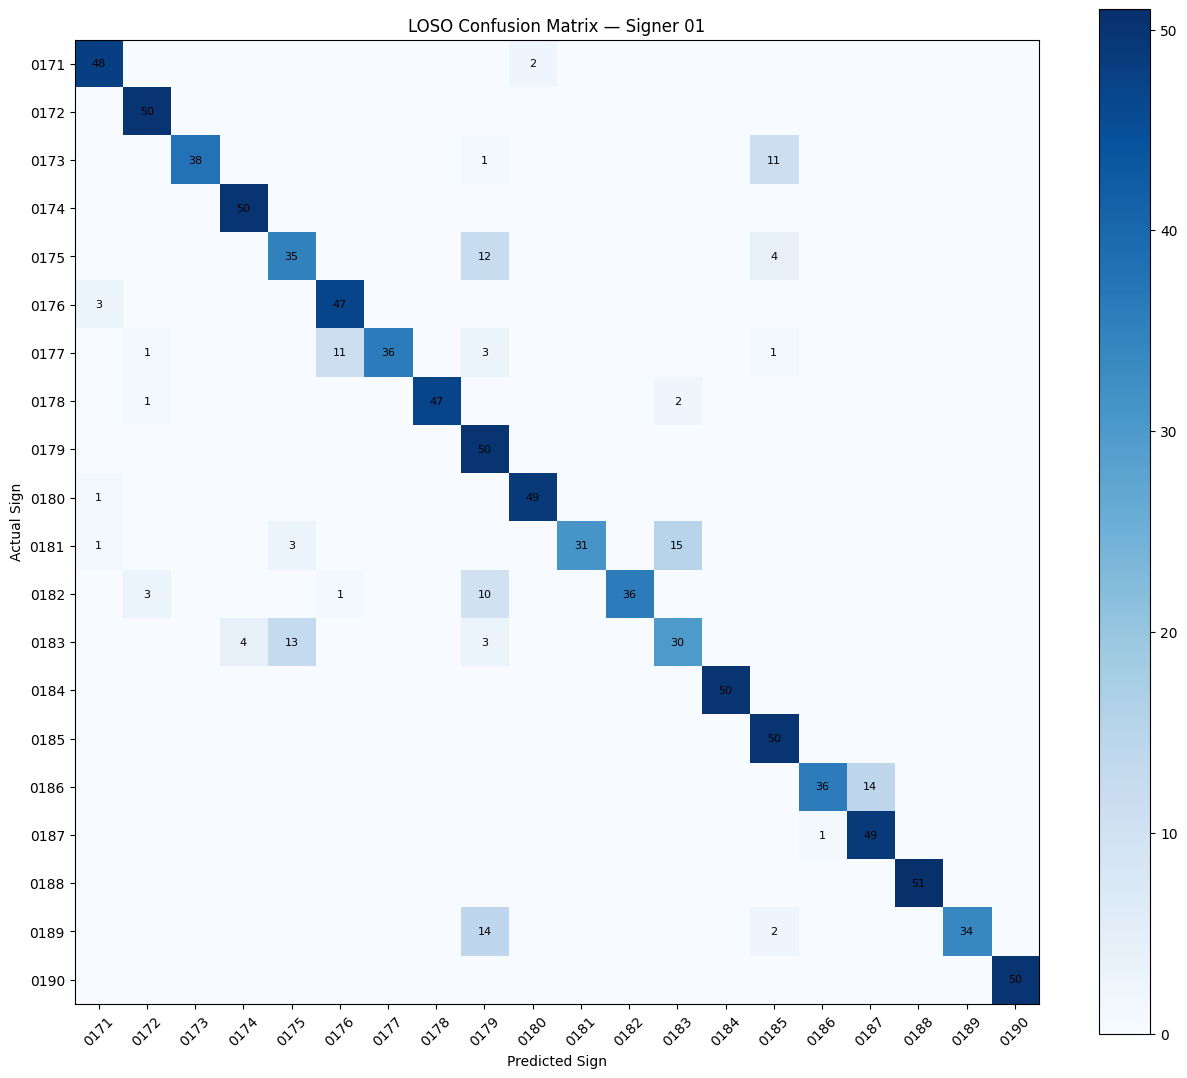


ERROR ANALYSIS — HELD-OUT SIGNER 02

BOTTOM 10 CLASSES BY RECALL
-----------------------------------------------------------------
Sign  Precision  Recall  F1-score  Support
0176      0.000   0.000     0.000     50.0
0185      1.000   0.154     0.267     52.0
0189      0.429   0.288     0.345     52.0
0174      0.951   0.780     0.857     50.0
0179      1.000   0.800     0.889     50.0
0178      1.000   0.840     0.913     50.0
0184      0.894   0.840     0.866     50.0
0186      1.000   0.900     0.947     50.0
0175      0.979   0.979     0.979     48.0
0182      1.000   0.980     0.990     51.0

TOP 10 CONFUSION PAIRS
-----------------------------------------------------------------
Actual Sign Predicted Sign  Count
       0176           0177     37
       0189           0177     27
       0185           0173     21
       0185           0189     20
       0176           0188     13
       0189           0176     10
       0174           0171      9
       0184           0188      8

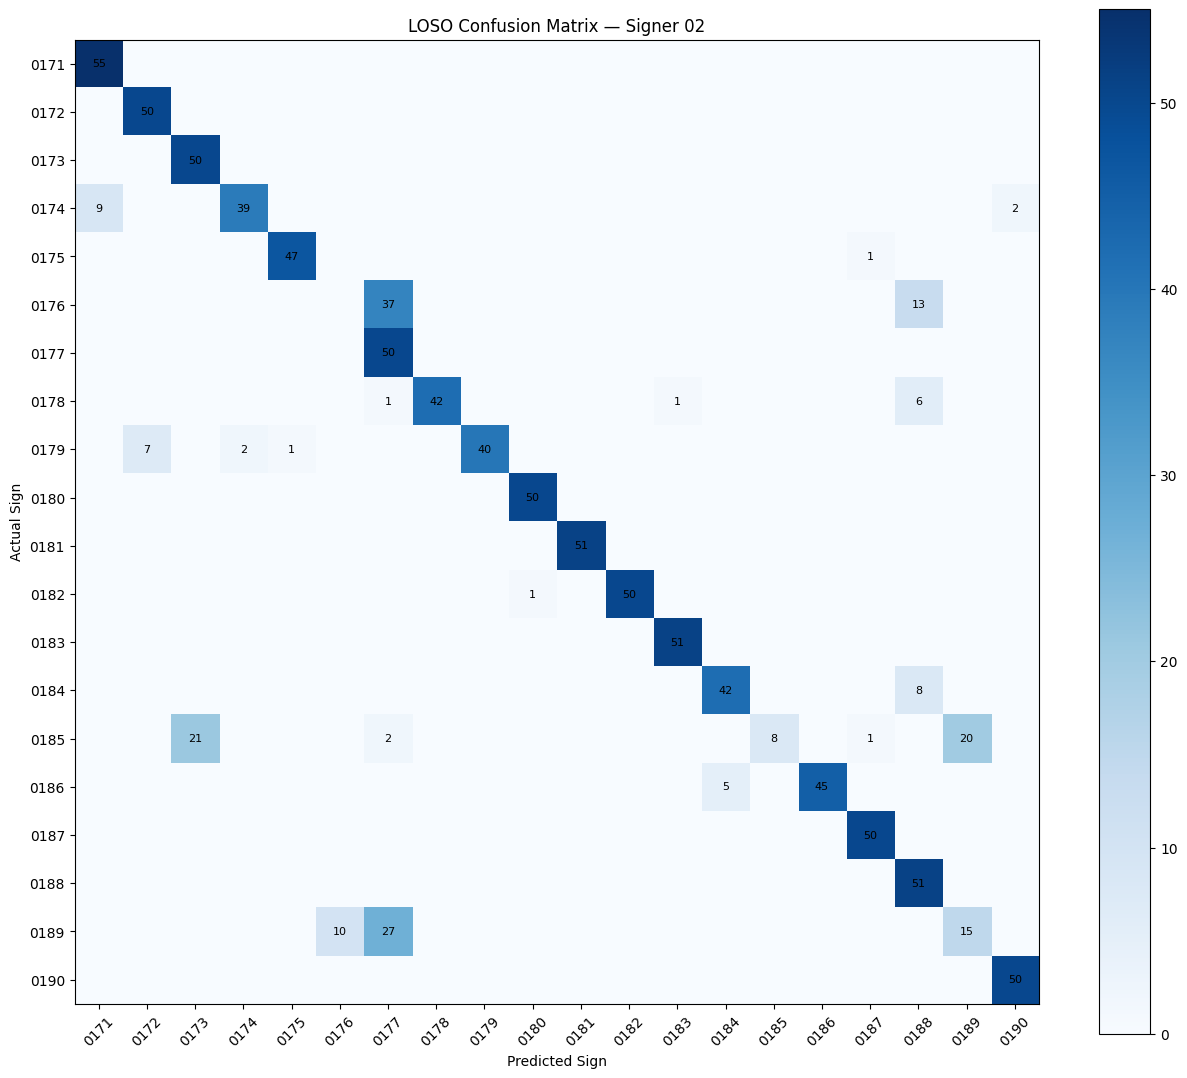


ERROR ANALYSIS — HELD-OUT SIGNER 03

BOTTOM 10 CLASSES BY RECALL
-----------------------------------------------------------------
Sign  Precision  Recall  F1-score  Support
0185      0.250   0.462     0.324     13.0
0173      0.774   0.480     0.593     50.0
0176      0.962   0.490     0.649     51.0
0177      0.653   0.980     0.784     50.0
0180      1.000   0.980     0.990     50.0
0174      1.000   0.980     0.990     51.0
0189      0.962   0.980     0.971     51.0
0171      0.981   1.000     0.990     51.0
0178      1.000   1.000     1.000     51.0
0175      1.000   1.000     1.000     25.0

TOP 10 CONFUSION PAIRS
-----------------------------------------------------------------
Actual Sign Predicted Sign  Count
       0176           0177     26
       0173           0185     17
       0185           0173      7
       0173           0182      5
       0173           0189      2
       0173           0186      2
       0174           0182      1
       0177           0176      1

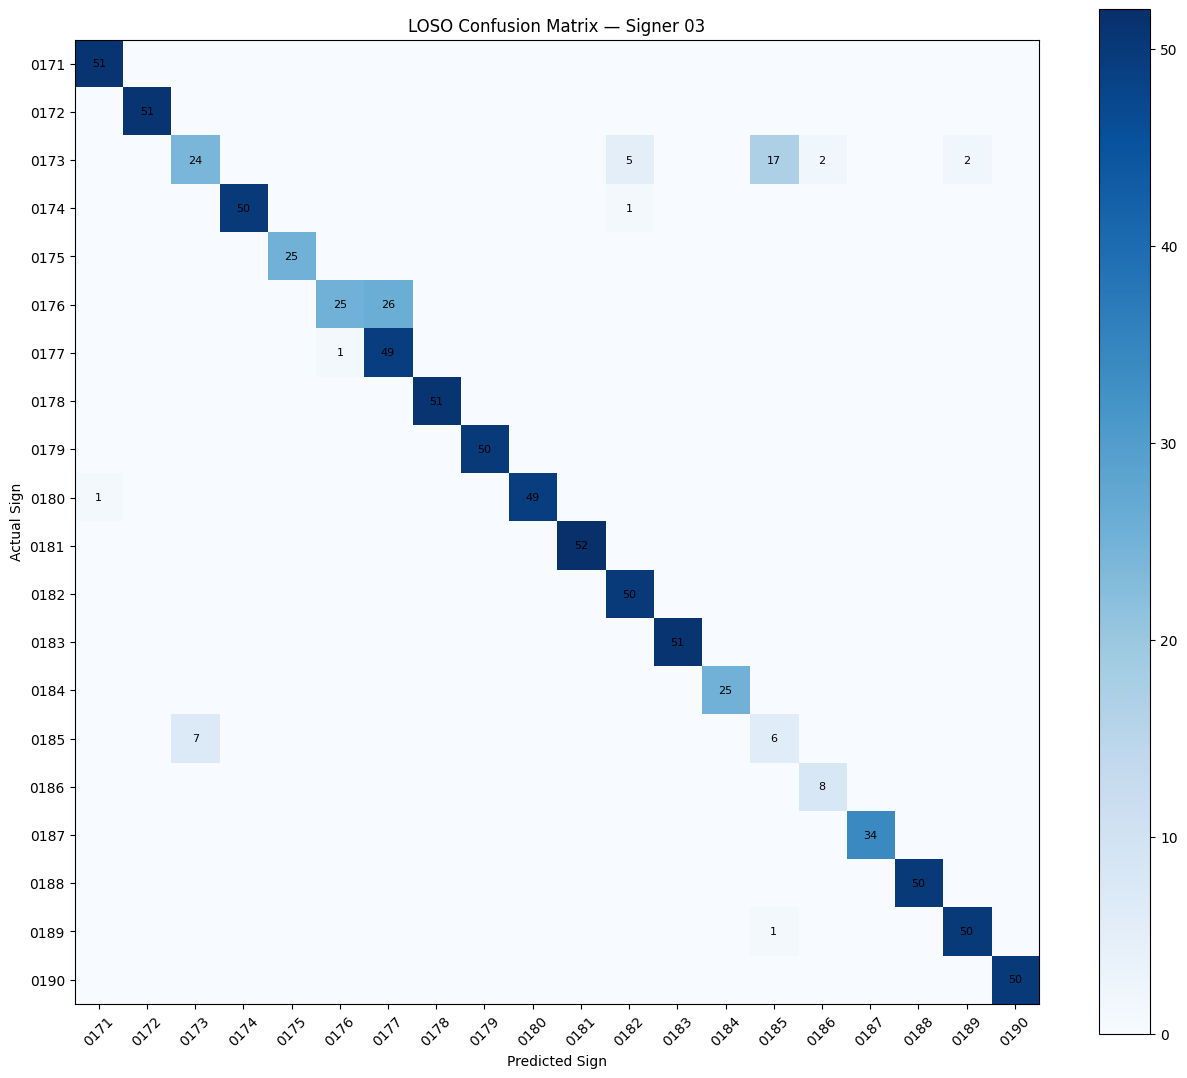


ERROR ANALYSIS COMPLETED
Results saved to: /content/drive/MyDrive/Sign_Language_Recognition/Pilot_20_Words/LOSO_Results/Error_Analysis


In [17]:
# ==========================================
# STEP 10 — LOSO ERROR ANALYSIS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report
from pathlib import Path

ERROR_DIR = PROJECT_DIR / "LOSO_Results" / "Error_Analysis"
ERROR_DIR.mkdir(parents=True, exist_ok=True)

class_labels = [str(c) for c in classes]

all_confusions = []

for signer, results in LOSO_TEST_RESULTS.items():

    print("\n" + "=" * 65)
    print(f"ERROR ANALYSIS — HELD-OUT SIGNER {signer}")
    print("=" * 65)

    y_true = np.asarray(results["y_true"])
    y_pred = np.asarray(results["y_pred"])

    # --------------------------------------
    # 1. Per-class performance
    # --------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(classes)),
        target_names=class_labels,
        output_dict=True,
        zero_division=0
    )

    class_results = []

    for label in class_labels:

        class_results.append({
            "Sign": label,
            "Precision": report[label]["precision"],
            "Recall": report[label]["recall"],
            "F1-score": report[label]["f1-score"],
            "Support": report[label]["support"]
        })

    class_df = pd.DataFrame(class_results)

    print("\nBOTTOM 10 CLASSES BY RECALL")
    print("-" * 65)

    print(
        class_df.sort_values("Recall")
        .head(10)
        .round(3)
        .to_string(index=False)
    )

    # --------------------------------------
    # 2. Find incorrect predictions
    # --------------------------------------

    error_mask = y_true != y_pred

    error_df = pd.DataFrame({
        "Actual": y_true[error_mask],
        "Predicted": y_pred[error_mask]
    })

    error_df["Actual Sign"] = error_df["Actual"].map(
        lambda x: class_labels[x]
    )

    error_df["Predicted Sign"] = error_df["Predicted"].map(
        lambda x: class_labels[x]
    )

    # --------------------------------------
    # 3. Most frequent confusion pairs
    # --------------------------------------

    confusion_pairs = (
        error_df.groupby(
            ["Actual Sign", "Predicted Sign"]
        )
        .size()
        .reset_index(name="Count")
        .sort_values("Count", ascending=False)
    )

    print("\nTOP 10 CONFUSION PAIRS")
    print("-" * 65)

    print(confusion_pairs.head(10).to_string(index=False))

    confusion_pairs["Held-out Signer"] = signer
    all_confusions.append(confusion_pairs)

    # --------------------------------------
    # 4. Save class performance
    # --------------------------------------

    class_df.to_csv(
        ERROR_DIR / f"signer_{signer}_class_performance.csv",
        index=False
    )

    confusion_pairs.to_csv(
        ERROR_DIR / f"signer_{signer}_confusion_pairs.csv",
        index=False
    )

    # --------------------------------------
    # 5. Plot confusion matrix
    # --------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(len(classes))
    )

    fig, ax = plt.subplots(figsize=(13, 11))

    im = ax.imshow(cm, cmap="Blues")

    ax.set_title(f"LOSO Confusion Matrix — Signer {signer}")
    ax.set_xlabel("Predicted Sign")
    ax.set_ylabel("Actual Sign")

    ax.set_xticks(np.arange(len(classes)))
    ax.set_yticks(np.arange(len(classes)))

    ax.set_xticklabels(class_labels, rotation=45)
    ax.set_yticklabels(class_labels)

    plt.colorbar(im, ax=ax)

    for i in range(len(classes)):
        for j in range(len(classes)):
            if cm[i, j] > 0:
                ax.text(
                    j, i, str(cm[i, j]),
                    ha="center",
                    va="center",
                    fontsize=8
                )

    plt.tight_layout()

    plt.savefig(
        ERROR_DIR / f"signer_{signer}_confusion_matrix.png",
        dpi=200
    )

    plt.show()
    plt.close()


# ==========================================
# 6. Combined confusion pairs
# ==========================================

combined_confusions = pd.concat(
    all_confusions,
    ignore_index=True
)

combined_confusions.to_csv(
    ERROR_DIR / "all_signers_confusion_pairs.csv",
    index=False
)

print("\n" + "=" * 65)
print("ERROR ANALYSIS COMPLETED")
print("=" * 65)

print("Results saved to:", ERROR_DIR)

OVERALL CLASS PERFORMANCE — ALL THREE SIGNERS
Sign  Correct  Total  Recall (%) Most Confused With  Confusion Count
0176       72    151       47.68               0177               63
0185       64    115       55.65               0173               28
0189       99    153       64.71               0177               27
0173      112    150       74.67               0185               28
0186       89    108       82.41               0187               14
0175      107    124       86.29               0179               12
0183      132    152       86.84               0175               13
0181      134    153       87.58               0183               15
0177      135    152       88.82               0176               12
0182      136    151       90.07               0179               10
0174      139    151       92.05               0171                9
0178      140    151       92.72               0188                6
0179      140    150       93.33               0172      

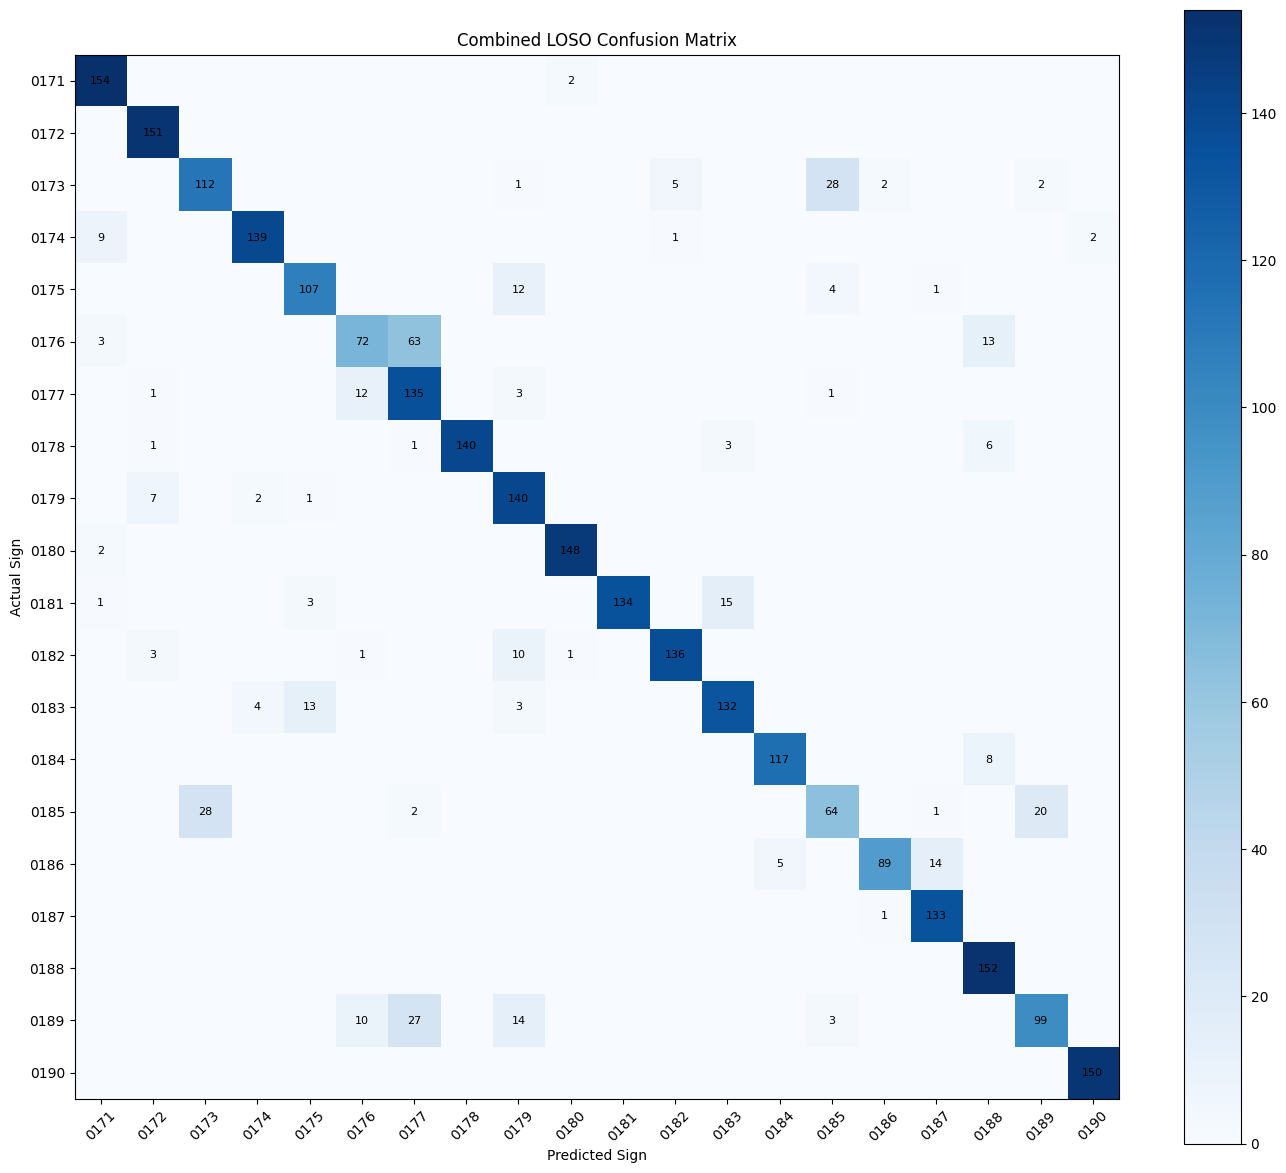


Saved combined analysis successfully.


In [18]:
# ==========================================
# STEP 11 — COMBINED LOSO CLASS ANALYSIS
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

class_labels = [str(c) for c in classes]

# --------------------------------------
# 1. Combine predictions from all signers
# --------------------------------------

all_true = np.concatenate([
    np.asarray(LOSO_TEST_RESULTS[s]["y_true"])
    for s in sorted(LOSO_TEST_RESULTS)
])

all_pred = np.concatenate([
    np.asarray(LOSO_TEST_RESULTS[s]["y_pred"])
    for s in sorted(LOSO_TEST_RESULTS)
])

cm = confusion_matrix(
    all_true,
    all_pred,
    labels=np.arange(len(classes))
)

# --------------------------------------
# 2. Overall per-class performance
# --------------------------------------

class_rows = []

for i, label in enumerate(class_labels):

    support = cm[i].sum()
    correct = cm[i, i]

    recall = correct / support if support else 0

    # Which wrong class received the most predictions?
    wrong_predictions = cm[i].copy()
    wrong_predictions[i] = 0

    most_confused_idx = np.argmax(wrong_predictions)

    class_rows.append({
        "Sign": label,
        "Correct": correct,
        "Total": support,
        "Recall (%)": recall * 100,
        "Most Confused With": (
            class_labels[most_confused_idx]
            if wrong_predictions[most_confused_idx] > 0
            else "-"
        ),
        "Confusion Count": wrong_predictions[most_confused_idx]
    })

overall_class_df = pd.DataFrame(class_rows)

print("OVERALL CLASS PERFORMANCE — ALL THREE SIGNERS")
print("=" * 85)

print(
    overall_class_df
    .sort_values("Recall (%)")
    .round(2)
    .to_string(index=False)
)

# --------------------------------------
# 3. Overall most frequent confusion pairs
# --------------------------------------

confusion_pairs = []

for actual_idx in range(len(classes)):
    for predicted_idx in range(len(classes)):

        if actual_idx != predicted_idx and cm[actual_idx, predicted_idx] > 0:

            confusion_pairs.append({
                "Actual": class_labels[actual_idx],
                "Predicted": class_labels[predicted_idx],
                "Count": cm[actual_idx, predicted_idx]
            })

confusion_pairs_df = pd.DataFrame(confusion_pairs)

confusion_pairs_df = confusion_pairs_df.sort_values(
    "Count",
    ascending=False
)

print("\nTOP 15 OVERALL CONFUSION PAIRS")
print("=" * 65)

print(confusion_pairs_df.head(15).to_string(index=False))

# --------------------------------------
# 4. Overall confusion matrix
# --------------------------------------

fig, ax = plt.subplots(figsize=(14, 12))

im = ax.imshow(cm, cmap="Blues")

ax.set_title("Combined LOSO Confusion Matrix")
ax.set_xlabel("Predicted Sign")
ax.set_ylabel("Actual Sign")

ax.set_xticks(np.arange(len(classes)))
ax.set_yticks(np.arange(len(classes)))

ax.set_xticklabels(class_labels, rotation=45)
ax.set_yticklabels(class_labels)

plt.colorbar(im, ax=ax)

for i in range(len(classes)):
    for j in range(len(classes)):
        if cm[i, j] > 0:
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=8
            )

plt.tight_layout()
plt.show()

# --------------------------------------
# 5. Save combined results
# --------------------------------------

ERROR_DIR = PROJECT_DIR / "LOSO_Results" / "Error_Analysis"

overall_class_df.to_csv(
    ERROR_DIR / "overall_class_performance.csv",
    index=False
)

confusion_pairs_df.to_csv(
    ERROR_DIR / "overall_confusion_pairs.csv",
    index=False
)

print("\nSaved combined analysis successfully.")


Signer 02
Misclassified samples: 37


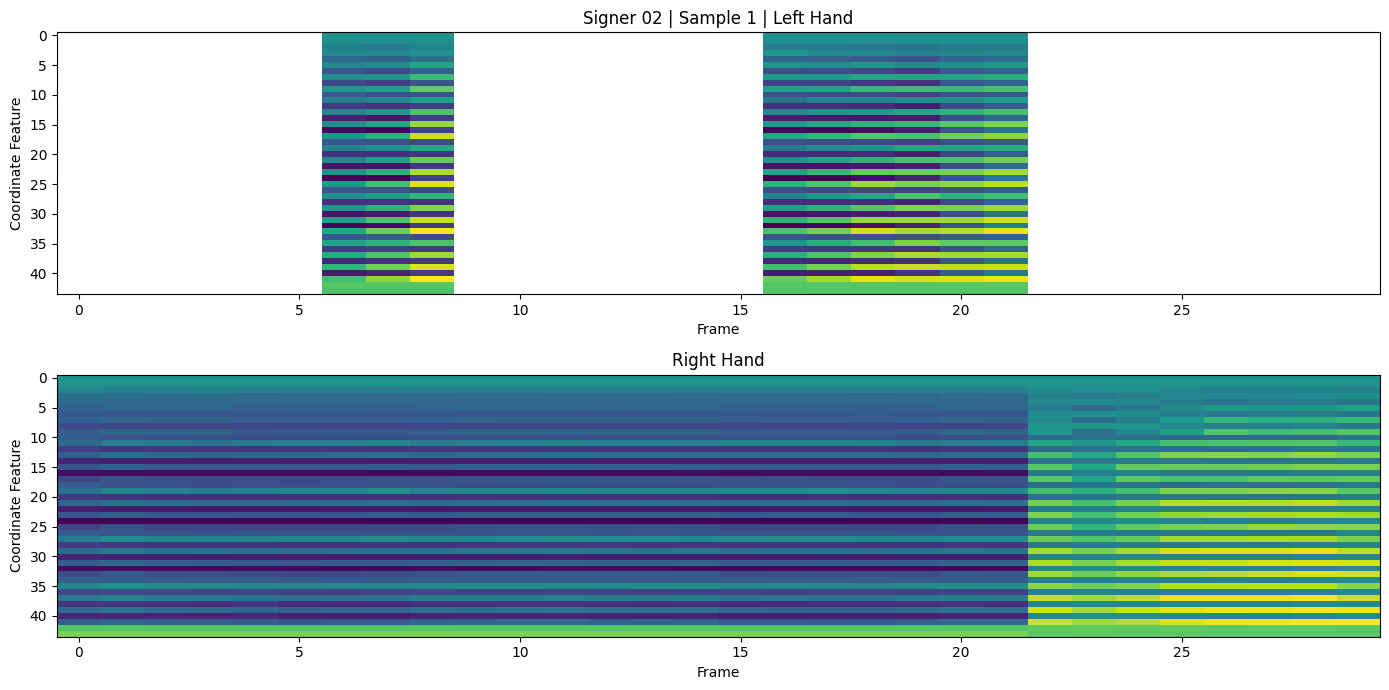

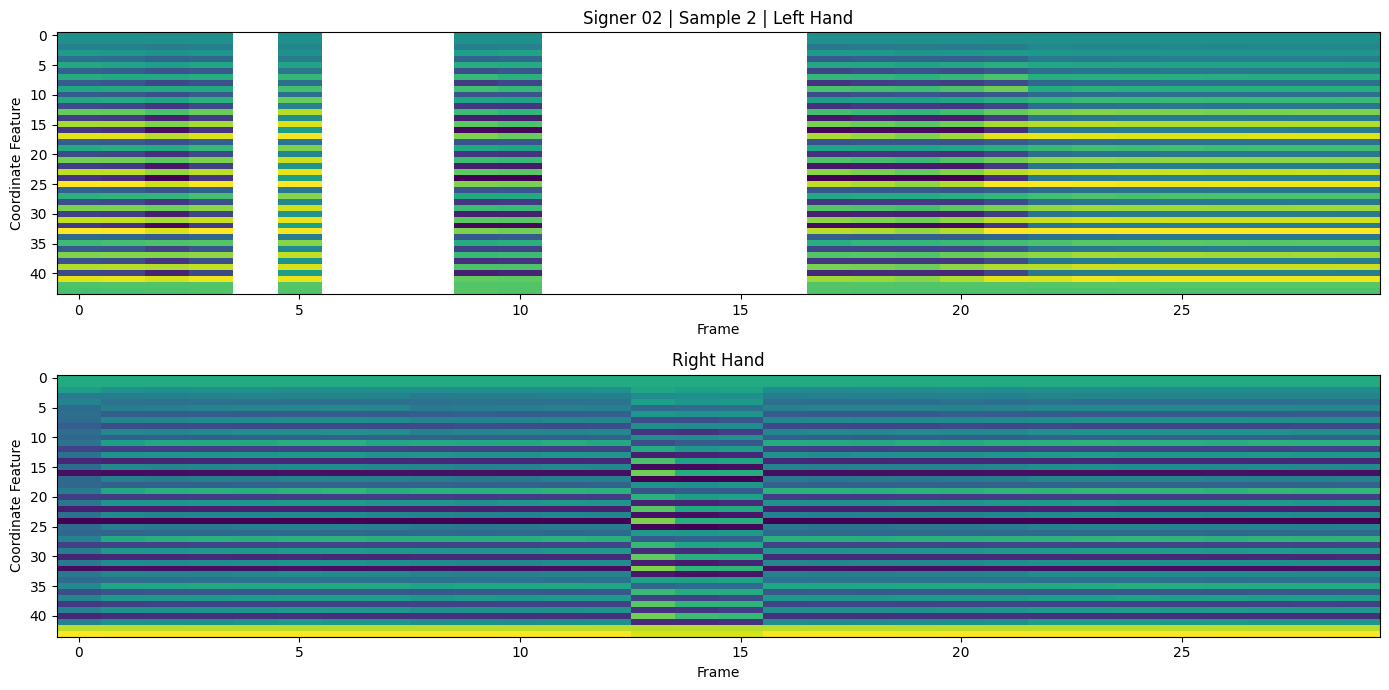


Signer 03
Misclassified samples: 26


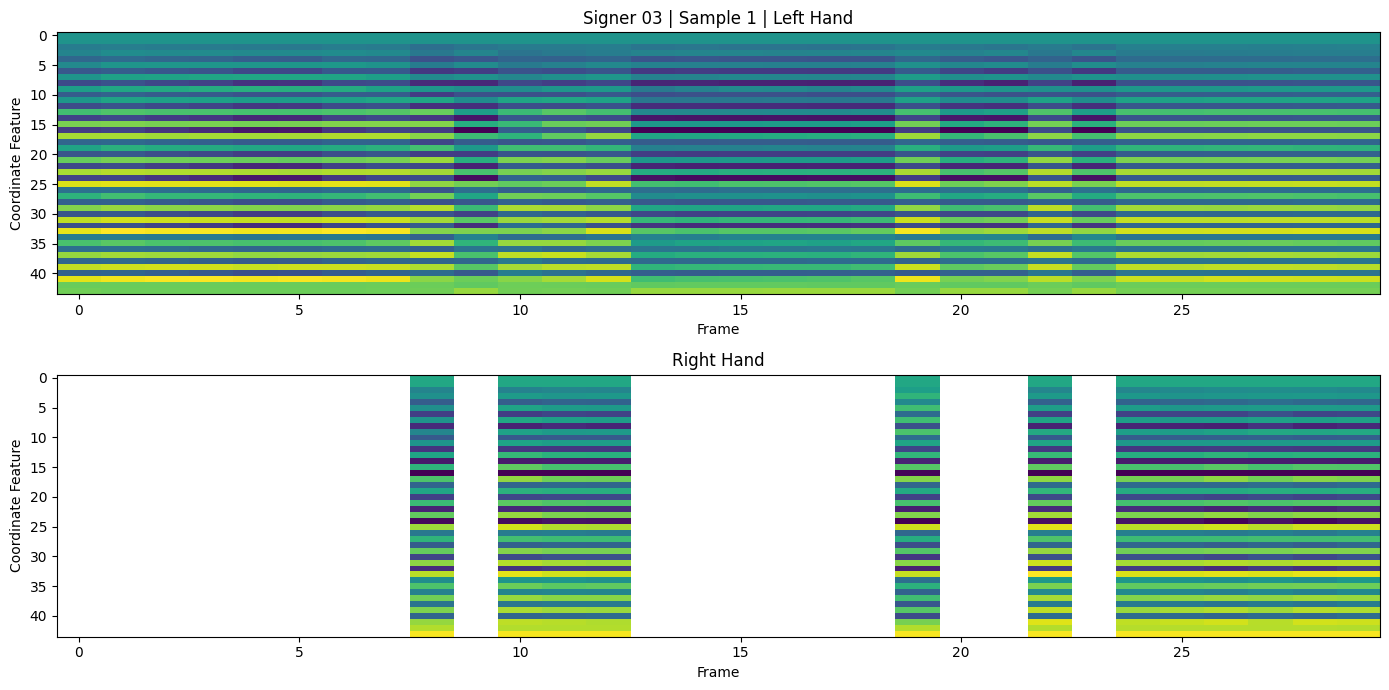

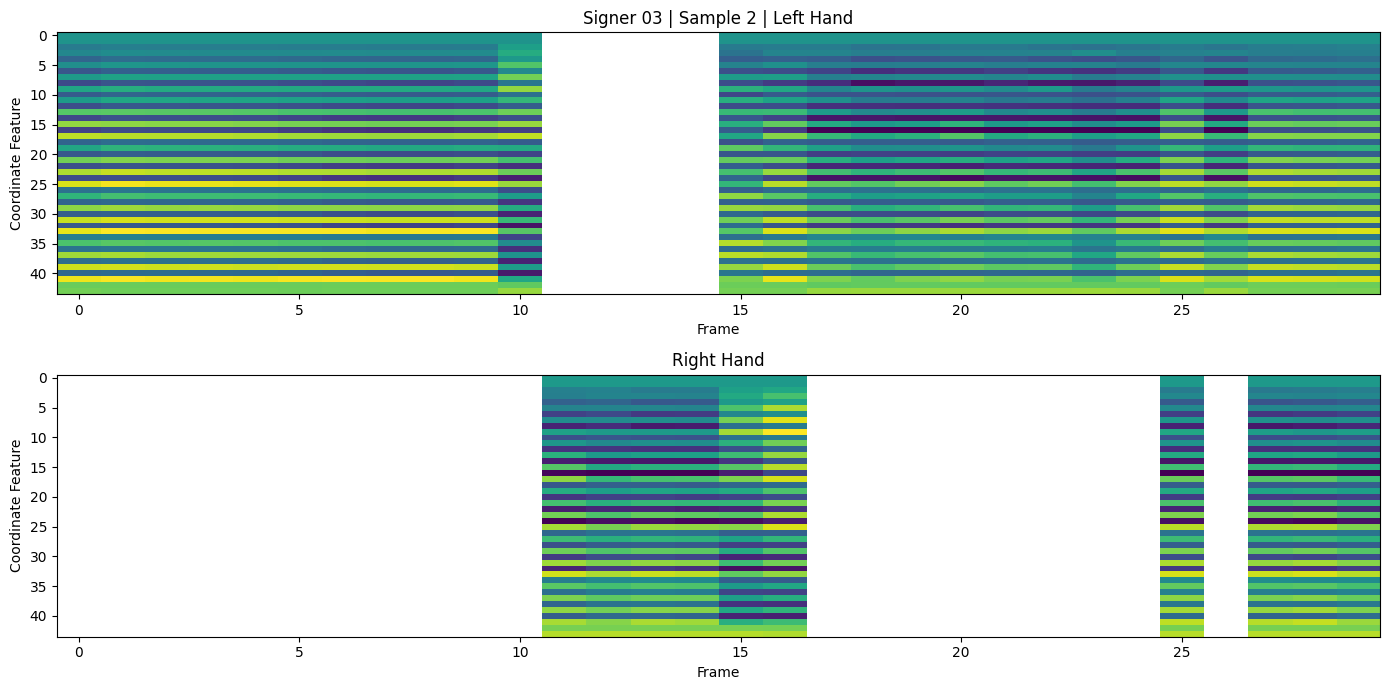

In [19]:
# ==========================================
# STEP 12 — EXTRACT MISCLASSIFIED SAMPLES
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

actual_class = classes.index("0176")
predicted_class = classes.index("0177")

for signer in ["02", "03"]:

    y_true = np.asarray(LOSO_TEST_RESULTS[signer]["y_true"])
    y_pred = np.asarray(LOSO_TEST_RESULTS[signer]["y_pred"])

    # Find samples where 0176 was predicted as 0177
    error_positions = np.where(
        (y_true == actual_class) &
        (y_pred == predicted_class)
    )[0]

    # Recover their original dataset indices
    test_indices = np.where(
        signers_all.astype(str) == signer
    )[0]

    original_indices = test_indices[error_positions]

    print(f"\nSigner {signer}")
    print("Misclassified samples:", len(original_indices))

    # Select up to two examples
    selected_indices = original_indices[:2]

    for sample_number, idx in enumerate(selected_indices, 1):

        sample = X_all_raw[idx]

        # Separate coordinates and detection flags
        left_hand = sample[:, :44]
        right_hand = sample[:, 44:88]

        fig, axes = plt.subplots(2, 1, figsize=(14, 7))

        axes[0].imshow(
            left_hand.T,
            aspect="auto",
            cmap="viridis"
        )
        axes[0].set_title(
            f"Signer {signer} | Sample {sample_number} | Left Hand"
        )
        axes[0].set_ylabel("Coordinate Feature")
        axes[0].set_xlabel("Frame")

        axes[1].imshow(
            right_hand.T,
            aspect="auto",
            cmap="viridis"
        )
        axes[1].set_title("Right Hand")
        axes[1].set_ylabel("Coordinate Feature")
        axes[1].set_xlabel("Frame")

        plt.tight_layout()
        plt.show()